# Medical insurance charges — Single-model OLS regression

Adapted from **Madrid_Rental_ML_Professor_Aligned.ipynb** to `insurance.csv`.

**Goal:** predict individual medical insurance `charges` from `age`, `sex`, `bmi`, `children`, `smoker`, and `region` using **one conventional ordinary least squares (OLS) model**. The original notebook's clustering, segment-specific models, full-versus-reduced model comparisons, and backward elimination have been removed. The retained approach includes dummy encoding, training-only imputation, VIF, regression tables, prediction metrics, residual diagnostics, and an untouched reserved validation set.

The data contains observed insurance charges; predictions are statistical associations, not causal estimates. Currency units are not specified by the CSV.

## 1. Imports and reproducible settings

In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display
import sys

ROOT = Path.cwd().parent        # notebooks/ -> project/
sys.path.append(str(ROOT))

from src.config import load_config

CONFIG_PATH = ROOT / "config.yaml"

cfg = load_config(CONFIG_PATH)
print(cfg)

DATA_PATH = ROOT / Path(cfg["paths"]["raw_data"])

DATA_PROCESSED_PATH = ROOT / Path(cfg["paths"]["processed_data"])
DATA_PREDICTIONS_PATH = ROOT / Path(cfg["paths"]["predictions"])

print(DATA_PREDICTIONS_PATH)

SEED = cfg['variables']['seed']


{'paths': {'raw_data': 'data/raw/insurance.csv', 'processed_data': 'data/processed/data.csv', 'predictions': 'data/inference'}, 'data': {'required_columns': ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], 'feature': ['age', 'sex', 'bmi', 'children', 'smoker', 'region'], 'target': 'charges'}, 'variables': {'seed': 47}}
c:\Files\Academics\2026-IE-MLOps-Course-Group4\data\inference


## 2. Load and audit the data

In [23]:
df = pd.read_csv(DATA_PATH)
TARGET = 'charges'
NUMERIC = ['age', 'bmi', 'children']
CATEGORICAL = ['sex', 'smoker', 'region']
PREDICTORS = NUMERIC + CATEGORICAL
assert set(PREDICTORS + [TARGET]).issubset(df.columns)
print('Shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum())
print('Missing values:\n', df.isna().sum())
print('Data types:\n', df.dtypes)
display(df.head())


Shape: (1338, 7)
Duplicate rows: 1
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Data types:
 age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Conservative cleaning

Convert numerical columns to numeric values and standardize categorical text. Missing target values are removed; predictor missingness, if present, is handled using only the training/development data. No rows are removed for high charges, and no domain-specific outlier corrections are made.

In [24]:
clean = df.copy()
for col in NUMERIC + [TARGET]:
    clean[col] = pd.to_numeric(clean[col], errors='coerce')
for col in CATEGORICAL:
    clean[col] = clean[col].astype('string').str.strip().str.lower()
clean = clean.dropna(subset=[TARGET]).copy()
print('Rows after target cleaning:', len(clean))
print('Missing values after cleaning:\n', clean.isna().sum())
print('Categorical levels:')
for col in CATEGORICAL:
    print(col, sorted(clean[col].dropna().unique().tolist()))


Rows after target cleaning: 1338
Missing values after cleaning:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Categorical levels:
sex ['female', 'male']
smoker ['no', 'yes']
region ['northeast', 'northwest', 'southeast', 'southwest']


## 4. Exploratory diagnostics

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


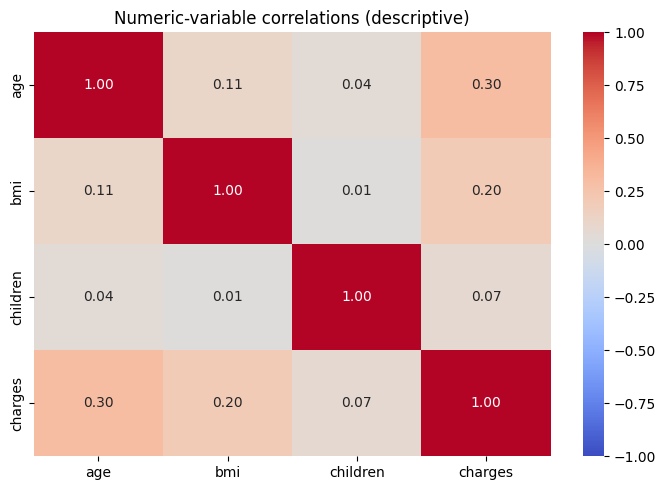

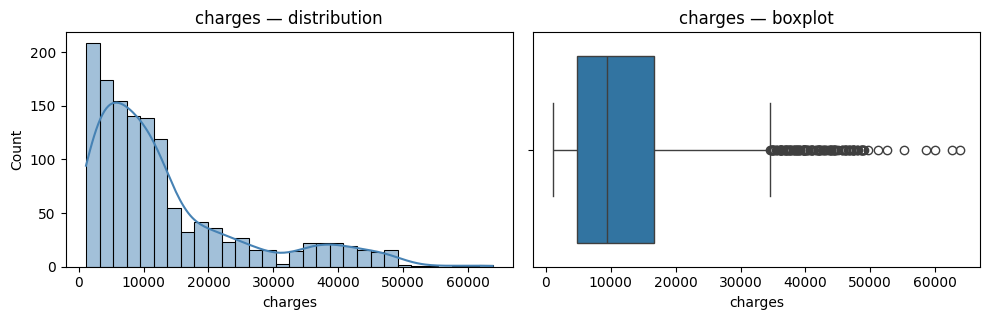

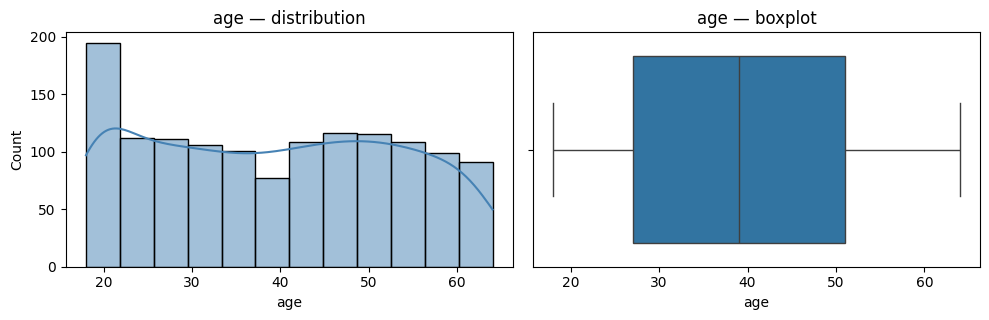

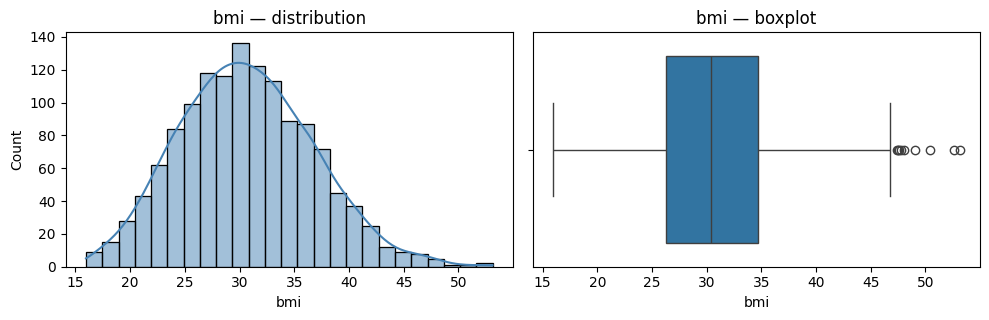

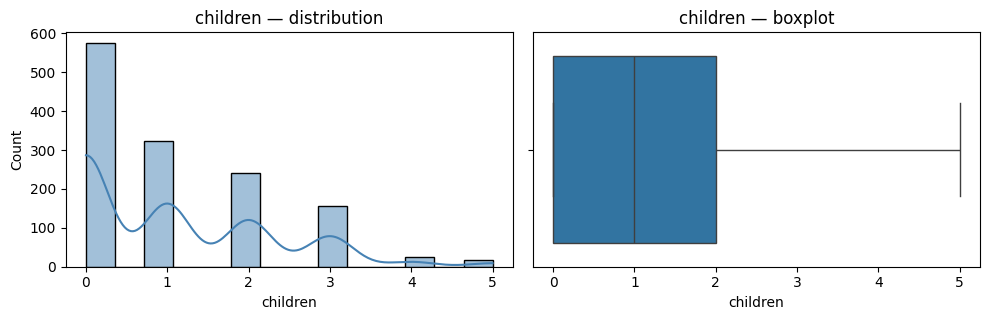

In [25]:
display(clean[NUMERIC + [TARGET]].describe().T)
plt.figure(figsize=(7, 5))
sns.heatmap(clean[NUMERIC + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numeric-variable correlations (descriptive)')
plt.tight_layout()
plt.show()
for col in ['charges', 'age', 'bmi', 'children']:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
    sns.histplot(x=clean[col].dropna(), kde=True, ax=axes[0], color="steelblue")
    axes[0].set_title(f'{col} — distribution')
    sns.boxplot(x=clean[col], ax=axes[1])
    axes[1].set_title(f'{col} — boxplot')
    plt.tight_layout()
    plt.show()


Charges by sex:


,count,median,mean
sex,,,
female,662,9412.96,12569.58
male,676,9369.62,13956.75


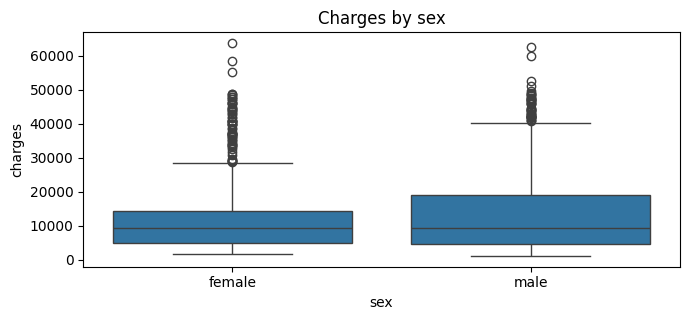

Charges by smoker:


,count,median,mean
smoker,,,
yes,274,34456.35,32050.23
no,1064,7345.41,8434.27


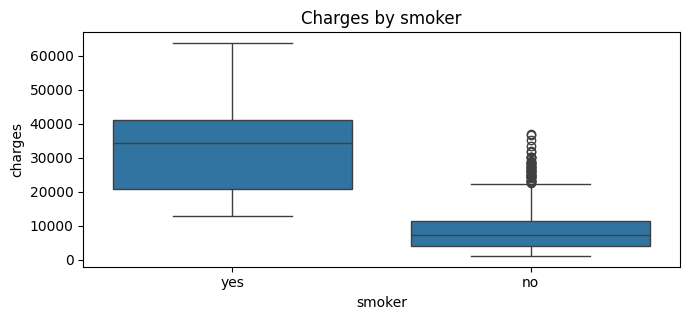

Charges by region:


,count,median,mean
region,,,
northeast,324,10057.65,13406.38
southeast,364,9294.13,14735.41
northwest,325,8965.80,12417.58
southwest,325,8798.59,12346.94


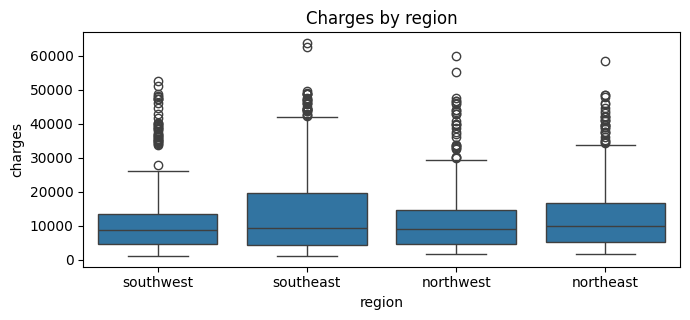

In [26]:
for col in CATEGORICAL:
    summary = clean.groupby(col, dropna=False)[TARGET].agg(['count', 'median', 'mean']).sort_values('median', ascending=False)
    print(f'Charges by {col}:')
    display(summary.round(2))
    plt.figure(figsize=(7, 3.3))
    sns.boxplot(data=clean, x=col, y=TARGET)
    plt.title(f'Charges by {col}')
    plt.tight_layout()
    plt.show()


## 5. Freeze development and reserved samples

Set aside 10% as a final reserved sample. Split the other 90% into training (75% of development) and test (25% of development). The reserved sample is not used to fit the model or choose features.

In [27]:
development, reserved = train_test_split(clean, test_size=0.10, random_state=SEED)
train, test = train_test_split(development, test_size=0.25, random_state=SEED)
print(f'Train: {len(train)} | Test: {len(test)} | Reserved: {len(reserved)}')
assert len(train) + len(test) + len(reserved) == len(clean)


Train: 903 | Test: 301 | Reserved: 134


## 6. Encode predictors and define the single OLS model

Use one-hot encoding with the first level of each categorical variable as its reference category, add an intercept, and impute any missing predictor values with training-only medians. Exactly **one model type and one fixed specification** are used throughout; final refitting on the development set does not introduce another candidate model.

In [28]:
def raw_features(frame):
    return pd.get_dummies(frame[PREDICTORS], columns=CATEGORICAL, drop_first=False, dtype=float).astype(float)

# Freeze category-reference choices using the training subset only.
train_all = raw_features(train)
reference = {}
for col in CATEGORICAL:
    dummy_cols = sorted(c for c in train_all.columns if c.startswith(f'{col}_'))
    reference[col] = dummy_cols[0] if dummy_cols else None
feature_columns = [c for c in train_all.columns if c not in reference.values()]

# Keep numeric features and available non-reference categories in one fixed design.
def prepare_features(frame, columns=feature_columns):
    return raw_features(frame).reindex(columns=columns, fill_value=0).astype(float)

imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(prepare_features(train)), columns=feature_columns, index=train.index)
X_test = pd.DataFrame(imputer.transform(prepare_features(test)), columns=feature_columns, index=test.index)

# One model: conventional price-level OLS.
def fit_ols(X, y):
    return sm.OLS(y, sm.add_constant(X, has_constant='add')).fit()

def predict_ols(model, X):
    return np.asarray(model.predict(sm.add_constant(X, has_constant='add')))

def scores(y, predicted):
    return {'R2': r2_score(y, predicted),
            'MAE': mean_absolute_error(y, predicted),
            'RMSE': np.sqrt(mean_squared_error(y, predicted))}

model = fit_ols(X_train, train[TARGET])
print('Reference categories:', reference)
print('Predictors:', feature_columns)
print(model.summary())


Reference categories: {'sex': 'sex_female', 'smoker': 'smoker_no', 'region': 'region_northeast'}
Predictors: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.746
Method:                 Least Squares   F-statistic:                     331.7
Date:                Tue, 03 Nov 2026   Prob (F-statistic):          1.70e-261
Time:                        15:31:46   Log-Likelihood:                -9155.5
No. Observations:                 903   AIC:                         1.833e+04
Df Residuals:                     894   BIC:                         1.837e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                              

## 7. VIF and conventional OLS diagnostics

,Term,VIF
7,region_southeast,1.661
8,region_southwest,1.517
6,region_northwest,1.515
2,bmi,1.115
1,age,1.018
5,smoker_yes,1.015
4,sex_male,1.011
3,children,1.006
0,const,1.000


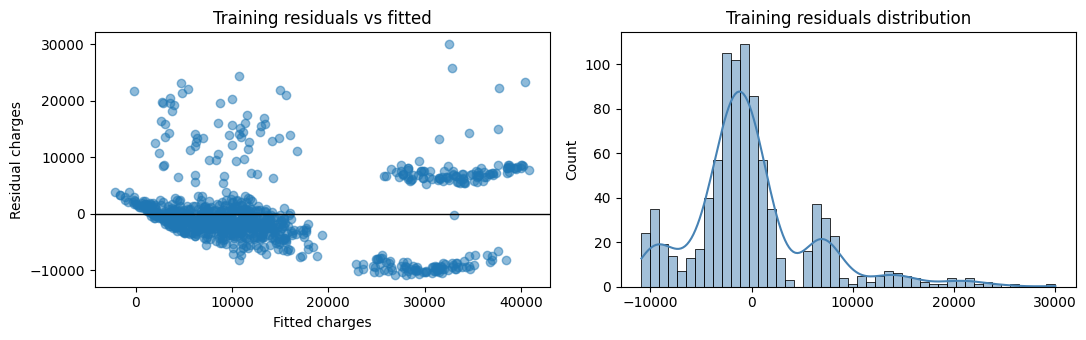

In [29]:
exog = pd.DataFrame(sm.add_constant(X_train, has_constant='add'), index=X_train.index)
vif = pd.DataFrame({'Term': exog.columns,
                    'VIF': [variance_inflation_factor(exog.to_numpy(dtype=float), i)
                            for i in range(exog.shape[1])]})
display(vif.sort_values('VIF', ascending=False).round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter(model.fittedvalues, model.resid, alpha=.5)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Training residuals vs fitted')
axes[0].set_xlabel('Fitted charges')
axes[0].set_ylabel('Residual charges')
sns.histplot(x=np.asarray(model.resid), kde=True, ax=axes[1], color="steelblue")
axes[1].set_title('Training residuals distribution')
plt.tight_layout()
plt.show()


## 8. Development evaluation (train and test)

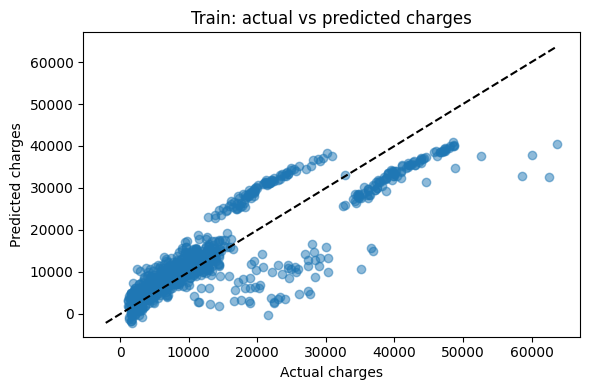

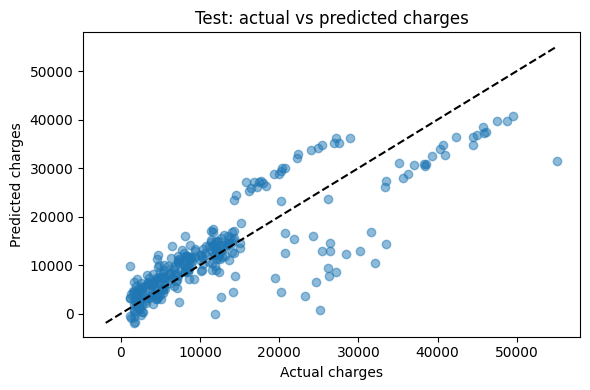

,Split,N,R2,MAE,RMSE
0,Train,903,0.748,4234.069,6124.266
1,Test,301,0.711,4144.802,6038.562


In [30]:
development_results = []
for label, X_part, part in [('Train', X_train, train), ('Test', X_test, test)]:
    pred = predict_ols(model, X_part)
    development_results.append({'Split': label, 'N': len(part), **scores(part[TARGET], pred)})
    plt.figure(figsize=(6, 4))
    plt.scatter(part[TARGET], pred, alpha=.5)
    limits = [min(part[TARGET].min(), pred.min()), max(part[TARGET].max(), pred.max())]
    plt.plot(limits, limits, 'k--')
    plt.title(f'{label}: actual vs predicted charges')
    plt.xlabel('Actual charges')
    plt.ylabel('Predicted charges')
    plt.tight_layout()
    plt.show()

development_scores = pd.DataFrame(development_results)
display(development_scores.round(3))
development_scores.to_csv(DATA_PREDICTIONS_PATH / 'development_scores.csv', index=False)


## 9. Refit the same model on development data and evaluate reserved data once

Following the original notebook's final-validation structure, refit the **same OLS formula** and preprocessing on all development rows, then evaluate only once on the untouched reserved subset.

,Model,N_development,N_reserved,R2,MAE,RMSE
0,OLS,1204,134,0.823,4035.387,5540.958


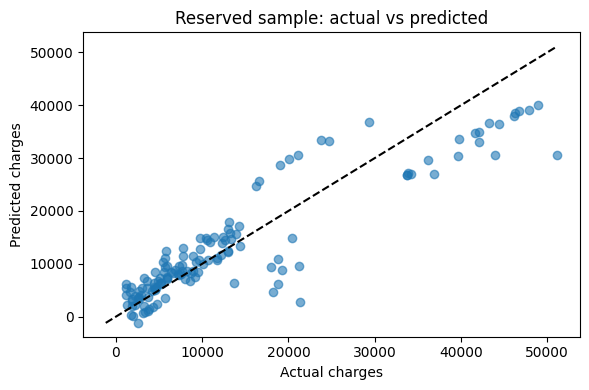

In [31]:
final_imputer = SimpleImputer(strategy='median')
X_dev = pd.DataFrame(final_imputer.fit_transform(prepare_features(development)), columns=feature_columns, index=development.index)
X_reserved = pd.DataFrame(final_imputer.transform(prepare_features(reserved)), columns=feature_columns, index=reserved.index)
final_model = fit_ols(X_dev, development[TARGET])
reserved_pred = predict_ols(final_model, X_reserved)
reserved_scores = pd.DataFrame([{'Model': 'OLS', 'N_development': len(development),
                                 'N_reserved': len(reserved), **scores(reserved[TARGET], reserved_pred)}])
display(reserved_scores.round(3))
reserved_scores.to_csv(DATA_PREDICTIONS_PATH / 'reserved_scores.csv', index=False)
reserved_predictions = reserved[PREDICTORS + [TARGET]].copy()
reserved_predictions['predicted_charges'] = reserved_pred
reserved_predictions['residual'] = reserved_predictions[TARGET] - reserved_predictions['predicted_charges']
reserved_predictions['absolute_error'] = reserved_predictions['residual'].abs()
reserved_predictions.to_csv(DATA_PREDICTIONS_PATH / 'reserved_predictions.csv', index=False)
plt.figure(figsize=(6, 4))
plt.scatter(reserved[TARGET], reserved_pred, alpha=.6)
limits = [min(reserved[TARGET].min(), reserved_pred.min()), max(reserved[TARGET].max(), reserved_pred.max())]
plt.plot(limits, limits, 'k--')
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.title('Reserved sample: actual vs predicted')
plt.tight_layout()
plt.show()


## 10. Final conventional OLS coefficient table

Categorical coefficients compare with the omitted reference level for that variable, controlling for the other predictors. These are associations, not causal effects.

In [32]:
print('Final OLS summary (fit on all development rows):')
print(final_model.summary())
coefficients = pd.DataFrame({
    'Term': final_model.params.index,
    'Coefficient': final_model.params.values,
    'Std_Error': final_model.bse.values,
    't_statistic': final_model.tvalues.values,
    'p_value': final_model.pvalues.values,
    'CI_low': final_model.conf_int().iloc[:, 0].values,
    'CI_high': final_model.conf_int().iloc[:, 1].values
})
display(coefficients.round(4))
coefficients.to_csv(DATA_PREDICTIONS_PATH / 'OLS_coefficients.csv', index=False)
print('Largest reserved-sample absolute errors:')
display(reserved_predictions.nlargest(5, 'absolute_error'))


Final OLS summary (fit on all development rows):
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.739
Method:                 Least Squares   F-statistic:                     427.0
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:31:47   Log-Likelihood:                -12202.
No. Observations:                1204   AIC:                         2.442e+04
Df Residuals:                    1195   BIC:                         2.447e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

,Term,Coefficient,Std_Error,t_statistic,p_value,CI_low,CI_high
0,const,-12096.9029,1054.5089,-11.4716,0.0000,-14165.7978,-10028.0081
1,age,261.3347,12.6612,20.6407,0.0000,236.4941,286.1752
2,bmi,338.2799,30.4430,11.1119,0.0000,278.5522,398.0075
3,children,436.3128,146.4773,2.9787,0.0030,148.9316,723.6940
4,sex_male,-16.9545,354.2217,-0.0479,0.9618,-711.9201,678.0111
5,smoker_yes,23454.0057,440.4787,53.2466,0.0000,22589.8080,24318.2033
6,region_northwest,-295.0318,506.8190,-0.5821,0.5606,-1289.3859,699.3224
7,region_southeast,-1048.5009,506.2031,-2.0713,0.0385,-2041.6467,-55.3552
8,region_southwest,-899.2880,508.3224,-1.7691,0.0771,-1896.5917,98.0157


Largest reserved-sample absolute errors:


,age,bmi,children,sex,smoker,region,charges,predicted_charges,residual,absolute_error
34,28,36.400,1,male,yes,southwest,51194.55914,30507.930341,20686.628799,20686.628799
102,18,30.115,0,female,no,northeast,21344.84670,2794.418941,18550.427759,18550.427759
858,25,32.230,1,female,no,southeast,18218.16139,4727.035295,13491.126095,13491.126095
587,34,30.210,1,female,yes,northwest,43943.87610,30603.196661,13340.679439,13340.679439
429,27,30.400,3,female,no,northwest,18804.75240,6256.747142,12548.005258,12548.005258


## 11. Reproducibility checks and exports

In [33]:
assert len(clean) == 1338, 'The supplied insurance.csv was expected to contain 1,338 rows.'
assert len(reserved_predictions) == len(reserved)
assert list(X_train.columns) == list(X_dev.columns)
assert len(development_scores) == 2 and len(reserved_scores) == 1
print('Input:', DATA_PATH)
print('One model: OLS, fixed specification')
print('Exports:')
for file in sorted(DATA_PREDICTIONS_PATH.glob('*.csv')):
    print(' -', file)


Input: c:\Files\Academics\2026-IE-MLOps-Course-Group4\data\raw\insurance.csv
One model: OLS, fixed specification
Exports:
 - c:\Files\Academics\2026-IE-MLOps-Course-Group4\data\inference\development_scores.csv
 - c:\Files\Academics\2026-IE-MLOps-Course-Group4\data\inference\OLS_coefficients.csv
 - c:\Files\Academics\2026-IE-MLOps-Course-Group4\data\inference\reserved_predictions.csv
 - c:\Files\Academics\2026-IE-MLOps-Course-Group4\data\inference\reserved_scores.csv
